In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    Holt,
    ExponentialSmoothing
)

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

PROJECT_DIR = r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"

FEATURE_DIR = os.path.join(PROJECT_DIR, "data", "features")
FORECAST_DIR = os.path.join(PROJECT_DIR, "data", "forecasts")
CHART_DIR = os.path.join(PROJECT_DIR, "outputs", "charts")
REPORT_DIR = os.path.join(PROJECT_DIR, "outputs", "reports")
MODEL_DIR = os.path.join(PROJECT_DIR, "outputs", "models")

for folder in [FORECAST_DIR, CHART_DIR, REPORT_DIR, MODEL_DIR]:
    os.makedirs(folder, exist_ok=True)

INSTRUMENTS = [
    "NIFTY50", "BANKNIFTY", "RELIANCE", "TCS", "HDFCBANK",
    "INFY", "ICICIBANK", "SBIN", "ITC", "LT"
]

TEST_SIZE = 0.20
MIN_TRAIN_ROWS = 300

print("Project directory:", PROJECT_DIR)
print("Forecasting setup completed.")

Project directory: C:\Users\adity\Downloads\Historical data\BharatMarket_AI
Forecasting setup completed.


In [3]:
def load_price_series(symbol):
    file_path = os.path.join(
        FEATURE_DIR,
        f"{symbol}_features_full.csv"
    )

    if not os.path.exists(file_path):
        raise FileNotFoundError(f"Missing file: {file_path}")

    df = pd.read_csv(file_path)

    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df = df.dropna(subset=["date"])
    df = df.sort_values("date")
    df = df.drop_duplicates(subset=["date"], keep="last")

    price_column = (
        "adj_close"
        if "adj_close" in df.columns
        and df["adj_close"].notna().any()
        else "close"
    )

    df[price_column] = pd.to_numeric(
        df[price_column], errors="coerce"
    )

    df = df.dropna(subset=[price_column])
    df = df[df[price_column] > 0]

    series = df.set_index("date")[price_column].astype(float)
    series.name = symbol

    return series


market_series = {}

for symbol in INSTRUMENTS:
    try:
        series = load_price_series(symbol)
        market_series[symbol] = series
        print(f"{symbol}: {len(series)} observations")
    except Exception as e:
        print(f"Could not load {symbol}: {e}")

print("\nSuccessfully loaded:", len(market_series), "instruments")

NIFTY50: 1236 observations
BANKNIFTY: 1235 observations
RELIANCE: 1237 observations
TCS: 1237 observations
HDFCBANK: 1237 observations
INFY: 1237 observations
ICICIBANK: 1237 observations
SBIN: 1237 observations
ITC: 1237 observations
LT: 1237 observations

Successfully loaded: 10 instruments


In [4]:
train_test_data = {}

for symbol, series in market_series.items():

    split_index = int(len(series) * (1 - TEST_SIZE))

    train = series.iloc[:split_index]
    test = series.iloc[split_index:]

    if len(train) < MIN_TRAIN_ROWS or len(test) < 30:
        print(f"Skipping {symbol}: insufficient observations.")
        continue

    train_test_data[symbol] = {
        "train": train,
        "test": test
    }

    print(
        f"{symbol}: Train = {len(train)}, "
        f"Test = {len(test)}, "
        f"Test begins = {test.index.min().date()}"
    )

NIFTY50: Train = 988, Test = 248, Test begins = 2025-11-20
BANKNIFTY: Train = 988, Test = 247, Test begins = 2025-11-21
RELIANCE: Train = 989, Test = 248, Test begins = 2025-11-21
TCS: Train = 989, Test = 248, Test begins = 2025-11-21
HDFCBANK: Train = 989, Test = 248, Test begins = 2025-11-21
INFY: Train = 989, Test = 248, Test begins = 2025-11-21
ICICIBANK: Train = 989, Test = 248, Test begins = 2025-11-21
SBIN: Train = 989, Test = 248, Test begins = 2025-11-21
ITC: Train = 989, Test = 248, Test begins = 2025-11-21
LT: Train = 989, Test = 248, Test begins = 2025-11-21


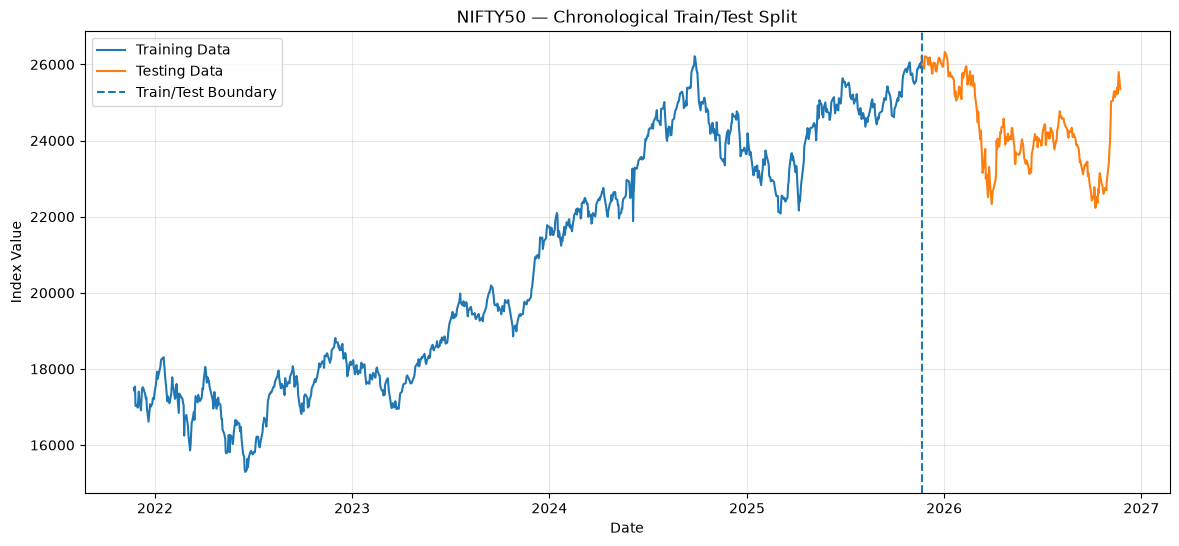

In [5]:
nifty_train = train_test_data["NIFTY50"]["train"]
nifty_test = train_test_data["NIFTY50"]["test"]

plt.figure(figsize=(14, 6))

plt.plot(nifty_train.index, nifty_train,
         label="Training Data")

plt.plot(nifty_test.index, nifty_test,
         label="Testing Data")

plt.axvline(
    nifty_test.index[0],
    linestyle="--",
    label="Train/Test Boundary"
)

plt.title("NIFTY50 — Chronological Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Index Value")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [6]:
def calculate_metrics(actual, predicted, previous_actual=None):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(predicted)

    actual = actual[valid]
    predicted = predicted[valid]

    if len(actual) == 0:
        return {
            "MAE": np.nan,
            "RMSE": np.nan,
            "MAPE": np.nan,
            "Directional_Accuracy": np.nan
        }

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    nonzero = actual != 0

    mape = (
        np.mean(np.abs(
            (actual[nonzero] - predicted[nonzero]) /
            actual[nonzero]
        )) * 100
        if nonzero.any()
        else np.nan
    )

    directional_accuracy = np.nan

    if previous_actual is not None:
        previous_actual = np.asarray(previous_actual, dtype=float)
        previous_actual = previous_actual[valid]

        actual_direction = np.sign(actual - previous_actual)
        predicted_direction = np.sign(predicted - previous_actual)

        directional_accuracy = np.mean(
            actual_direction == predicted_direction
        ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "Directional_Accuracy": directional_accuracy
    }

In [7]:
def forecast_naive(train, horizon):
    return np.repeat(train.iloc[-1], horizon)


def forecast_moving_average(train, horizon, window=20):
    average = train.tail(window).mean()
    return np.repeat(average, horizon)


def forecast_ses(train, horizon):
    model = SimpleExpSmoothing(
        train,
        initialization_method="estimated"
    )

    fitted = model.fit(optimized=True)
    return fitted.forecast(horizon)


def forecast_holt(train, horizon):
    model = Holt(
        train,
        initialization_method="estimated"
    )

    fitted = model.fit(optimized=True)
    return fitted.forecast(horizon)


def forecast_holt_winters(train, horizon):
    model = ExponentialSmoothing(
        train,
        trend="add",
        seasonal="add",
        seasonal_periods=5,
        initialization_method="estimated"
    )

    fitted = model.fit(optimized=True)
    return fitted.forecast(horizon)


def forecast_arima(train, horizon):
    model = ARIMA(
        train,
        order=(1, 1, 1)
    )

    fitted = model.fit()
    return fitted.forecast(steps=horizon)

In [8]:
nifty_train = train_test_data["NIFTY50"]["train"]
nifty_test = train_test_data["NIFTY50"]["test"]

horizon = len(nifty_test)

nifty_predictions = {}
nifty_metrics = []

MODEL_FUNCTIONS = {
    "Naive": forecast_naive,
    "Moving Average 20": forecast_moving_average,
    "SES": forecast_ses,
    "Holt Linear": forecast_holt,
    "Holt-Winters": forecast_holt_winters,
    "ARIMA(1,1,1)": forecast_arima
}

for model_name, model_function in MODEL_FUNCTIONS.items():

    try:
        prediction = model_function(nifty_train, horizon)

        prediction = pd.Series(
            np.asarray(prediction),
            index=nifty_test.index,
            name=model_name
        )

        nifty_predictions[model_name] = prediction

        metrics = calculate_metrics(
            nifty_test.values,
            prediction.values,
            previous_actual=nifty_train.iloc[-1:].tolist()
            + nifty_test.iloc[:-1].tolist()
        )

        nifty_metrics.append({
            "Instrument": "NIFTY50",
            "Model": model_name,
            **metrics
        })

        print(f"{model_name}: completed")

    except Exception as e:
        print(f"{model_name}: failed — {e}")

nifty_metrics_df = pd.DataFrame(nifty_metrics)

display(
    nifty_metrics_df.sort_values("RMSE").reset_index(drop=True)
)

Naive: completed
Moving Average 20: completed
SES: failed — No supported index is available.
Holt Linear: failed — No supported index is available.
Holt-Winters: failed — No supported index is available.
ARIMA(1,1,1): failed — No supported index is available.


,Instrument,Model,MAE,RMSE,MAPE,Directional_Accuracy
0,NIFTY50,Moving Average 20,1523.574901,1819.337913,6.446532,53.225806
1,NIFTY50,Naive,1706.817280,2011.096548,7.214312,51.612903


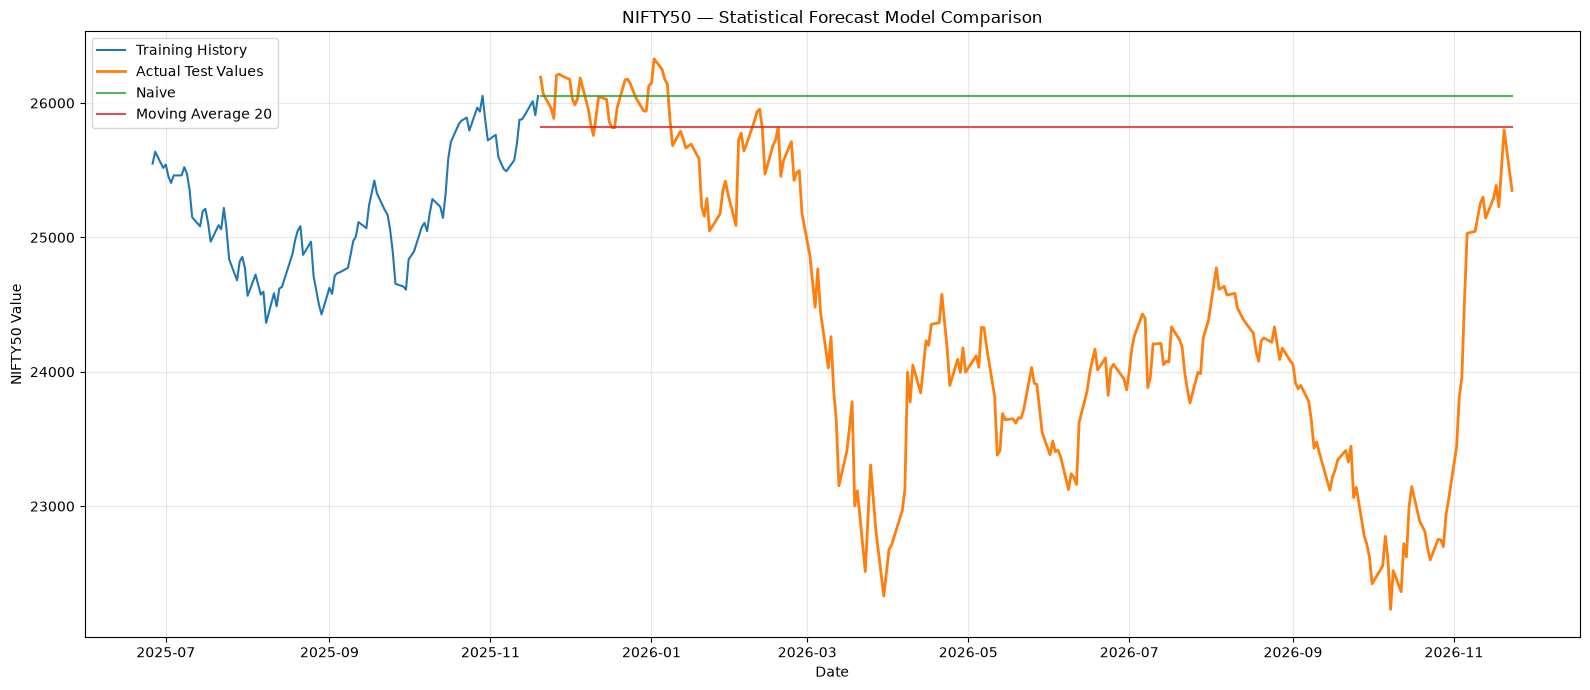

In [9]:
plt.figure(figsize=(16, 7))

plt.plot(
    nifty_train.index[-100:],
    nifty_train.iloc[-100:],
    label="Training History"
)

plt.plot(
    nifty_test.index,
    nifty_test,
    label="Actual Test Values",
    linewidth=2
)

for model_name, prediction in nifty_predictions.items():
    plt.plot(
        prediction.index,
        prediction.values,
        label=model_name,
        alpha=0.8
    )

plt.title("NIFTY50 — Statistical Forecast Model Comparison")
plt.xlabel("Date")
plt.ylabel("NIFTY50 Value")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
sarima_prediction = None

try:
    sarima_model = SARIMAX(
        nifty_train,
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 5),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    sarima_fitted = sarima_model.fit(disp=False)

    sarima_prediction = pd.Series(
        sarima_fitted.forecast(steps=horizon).values,
        index=nifty_test.index,
        name="SARIMA"
    )

    nifty_predictions["SARIMA(1,1,1)(1,0,1,5)"] = sarima_prediction

    sarima_metrics = calculate_metrics(
        nifty_test.values,
        sarima_prediction.values,
        previous_actual=nifty_train.iloc[-1:].tolist()
        + nifty_test.iloc[:-1].tolist()
    )

    nifty_metrics.append({
        "Instrument": "NIFTY50",
        "Model": "SARIMA(1,1,1)(1,0,1,5)",
        **sarima_metrics
    })

    nifty_metrics_df = pd.DataFrame(nifty_metrics)

    print("SARIMA completed successfully.")

except Exception as e:
    print("SARIMA could not be fitted:", e)

SARIMA could not be fitted: No supported index is available.


In [11]:
display(
    nifty_metrics_df.sort_values("RMSE").reset_index(drop=True)
)

,Instrument,Model,MAE,RMSE,MAPE,Directional_Accuracy
0,NIFTY50,Moving Average 20,1523.574901,1819.337913,6.446532,53.225806
1,NIFTY50,Naive,1706.817280,2011.096548,7.214312,51.612903


In [12]:
all_predictions = {}
all_metrics = []

for symbol, data in train_test_data.items():

    train = data["train"]
    test = data["test"]
    horizon = len(test)

    print(f"\nProcessing {symbol}...")

    for model_name, model_function in MODEL_FUNCTIONS.items():

        try:
            prediction = model_function(train, horizon)

            prediction = pd.Series(
                np.asarray(prediction),
                index=test.index
            )

            all_predictions[(symbol, model_name)] = prediction

            previous_values = (
                train.iloc[-1:].tolist()
                + test.iloc[:-1].tolist()
            )

            metrics = calculate_metrics(
                test.values,
                prediction.values,
                previous_actual=previous_values
            )

            all_metrics.append({
                "Instrument": symbol,
                "Model": model_name,
                **metrics
            })

            print(f"  {model_name}: completed")

        except Exception as e:
            print(f"  {model_name}: failed — {e}")

    if symbol == "NIFTY50" and sarima_prediction is not None:
        all_predictions[
            (symbol, "SARIMA(1,1,1)(1,0,1,5)")
        ] = sarima_prediction

        sarima_row = next(
            (
                row for row in nifty_metrics
                if row["Model"] == "SARIMA(1,1,1)(1,0,1,5)"
            ),
            None
        )

        if sarima_row:
            all_metrics.append(sarima_row)

metrics_df = pd.DataFrame(all_metrics)

display(metrics_df.head(20))
print("\nTotal model evaluations:", len(metrics_df))


Processing NIFTY50...
  Naive: completed
  Moving Average 20: completed
  SES: failed — No supported index is available.
  Holt Linear: failed — No supported index is available.
  Holt-Winters: failed — No supported index is available.
  ARIMA(1,1,1): failed — No supported index is available.

Processing BANKNIFTY...
  Naive: completed
  Moving Average 20: completed
  SES: failed — No supported index is available.
  Holt Linear: failed — No supported index is available.
  Holt-Winters: failed — No supported index is available.
  ARIMA(1,1,1): failed — No supported index is available.

Processing RELIANCE...
  Naive: completed
  Moving Average 20: completed
  SES: failed — No supported index is available.
  Holt Linear: failed — No supported index is available.
  Holt-Winters: failed — No supported index is available.
  ARIMA(1,1,1): failed — No supported index is available.

Processing TCS...
  Naive: completed
  Moving Average 20: completed
  SES: failed — No supported index is avail

,Instrument,Model,MAE,RMSE,MAPE,Directional_Accuracy
0,NIFTY50,Naive,1706.817280,2011.096548,7.214312,51.612903
1,NIFTY50,Moving Average 20,1523.574901,1819.337913,6.446532,53.225806
2,BANKNIFTY,Naive,2583.721597,3219.899437,4.645027,50.202429
3,BANKNIFTY,Moving Average 20,2152.071266,2650.957416,3.834403,49.797571
4,RELIANCE,Naive,188.384367,211.594926,14.489491,50.403226
5,RELIANCE,Moving Average 20,147.544428,166.692434,11.342588,49.596774
6,TCS,Naive,555.676456,630.643680,24.298817,43.951613
7,TCS,Moving Average 20,511.189550,569.797784,22.221302,43.145161
8,HDFCBANK,Naive,183.864183,205.790608,24.259168,42.338710
9,HDFCBANK,Moving Average 20,170.288945,192.962991,22.537887,45.564516



Total model evaluations: 20


In [13]:
metrics_df.to_csv(
    os.path.join(REPORT_DIR, "statistical_forecasting_metrics.csv"),
    index=False
)

for metric in ["MAE", "RMSE", "MAPE", "Directional_Accuracy"]:

    pivot = metrics_df.pivot_table(
        index="Instrument",
        columns="Model",
        values=metric
    )

    print(f"\n{metric} comparison")
    display(pivot.round(3))


MAE comparison


Model,Moving Average 20,Naive
Instrument,,
BANKNIFTY,2152.071,2583.722
HDFCBANK,170.289,183.864
ICICIBANK,60.119,59.738
INFY,265.626,282.839
ITC,92.712,87.385
LT,145.251,141.943
NIFTY50,1523.575,1706.817
RELIANCE,147.544,188.384
SBIN,90.443,64.356



RMSE comparison


Model,Moving Average 20,Naive
Instrument,,
BANKNIFTY,2650.957,3219.899
HDFCBANK,192.963,205.791
ICICIBANK,80.999,81.071
INFY,291.471,314.622
ITC,99.024,94.017
LT,184.836,193.099
NIFTY50,1819.338,2011.097
RELIANCE,166.692,211.595
SBIN,110.057,86.337



MAPE comparison


Model,Moving Average 20,Naive
Instrument,,
BANKNIFTY,3.834,4.645
HDFCBANK,22.538,24.259
ICICIBANK,4.391,4.428
INFY,23.610,25.292
ITC,32.542,30.738
LT,3.737,3.720
NIFTY50,6.447,7.214
RELIANCE,11.343,14.489
SBIN,8.510,5.989



Directional_Accuracy comparison


Model,Moving Average 20,Naive
Instrument,,
BANKNIFTY,49.798,50.202
HDFCBANK,45.565,42.339
ICICIBANK,53.226,49.597
INFY,44.355,43.548
ITC,45.161,45.968
LT,56.452,54.839
NIFTY50,53.226,51.613
RELIANCE,49.597,50.403
SBIN,46.371,50.403


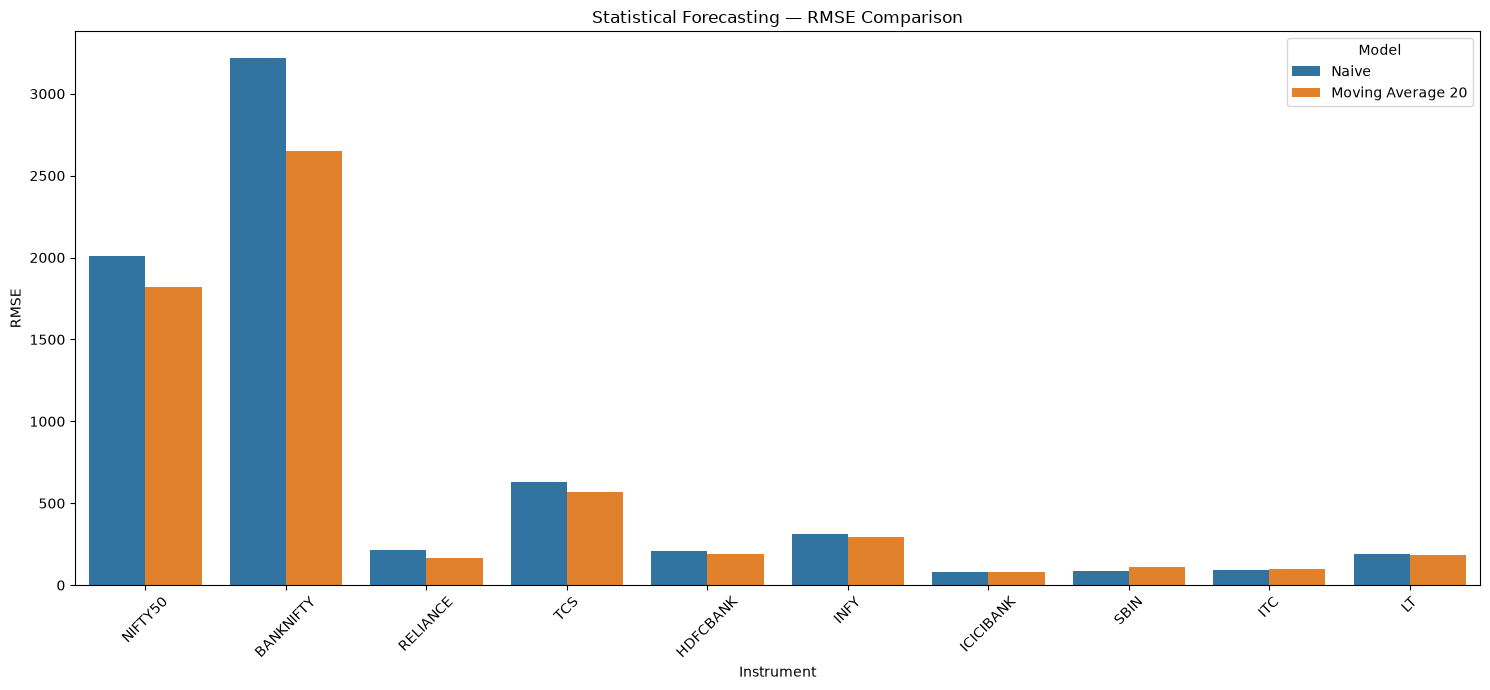

In [14]:
plt.figure(figsize=(15, 7))

sns.barplot(
    data=metrics_df,
    x="Instrument",
    y="RMSE",
    hue="Model"
)

plt.title("Statistical Forecasting — RMSE Comparison")
plt.xticks(rotation=45)
plt.ylabel("RMSE")
plt.tight_layout()
plt.show()

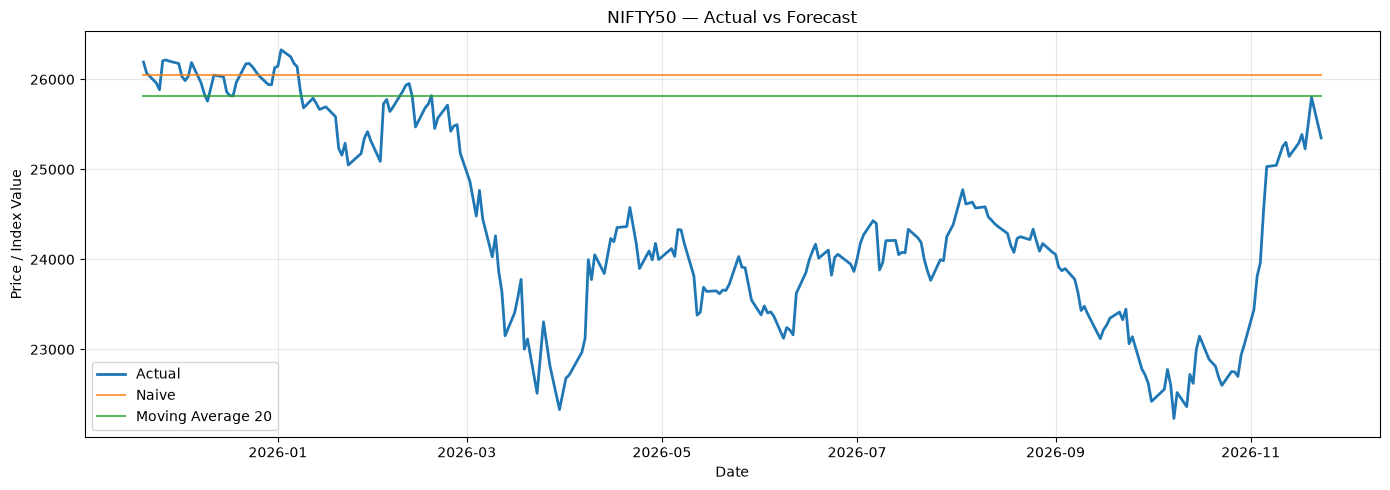

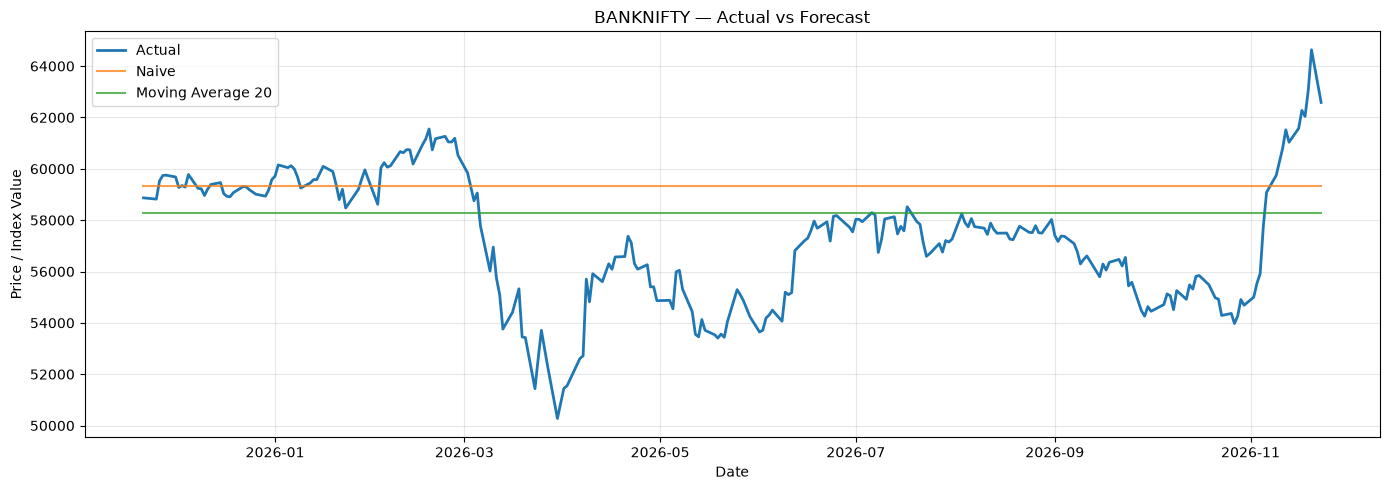

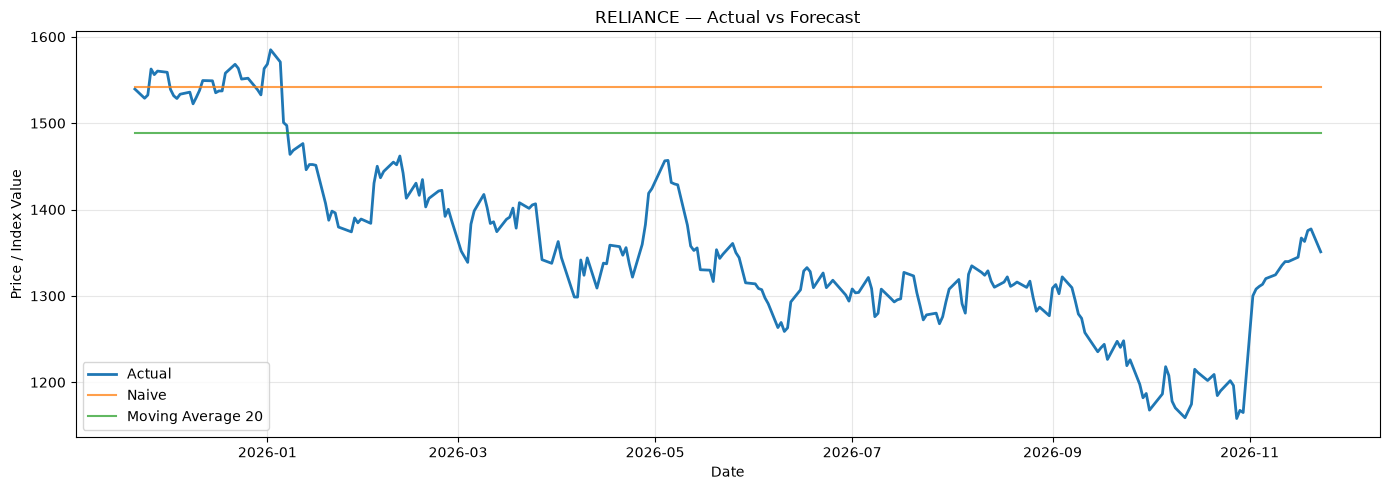

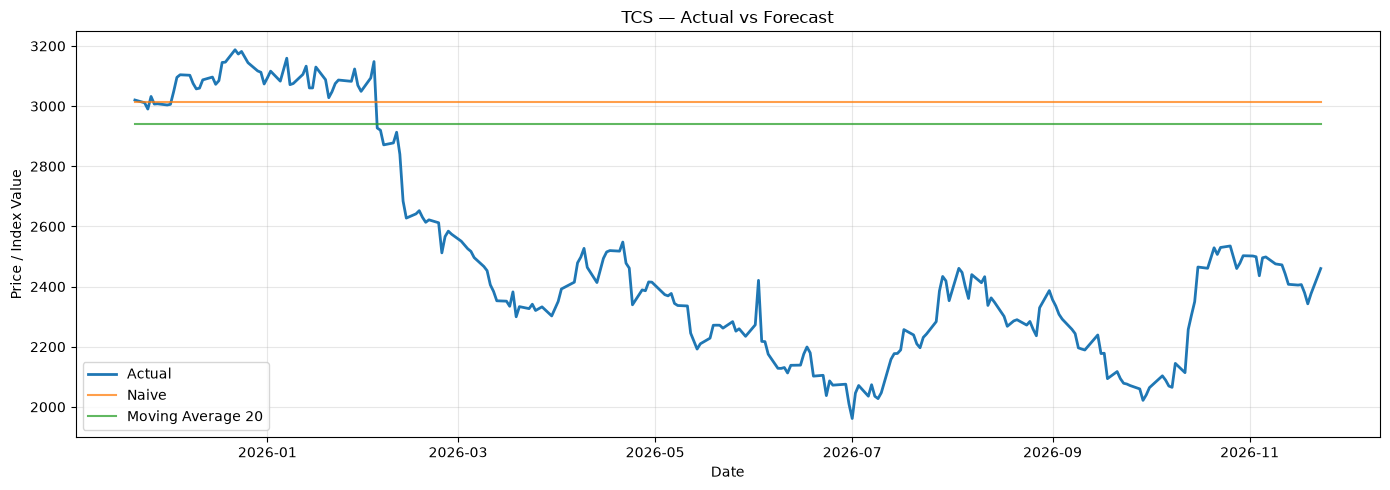

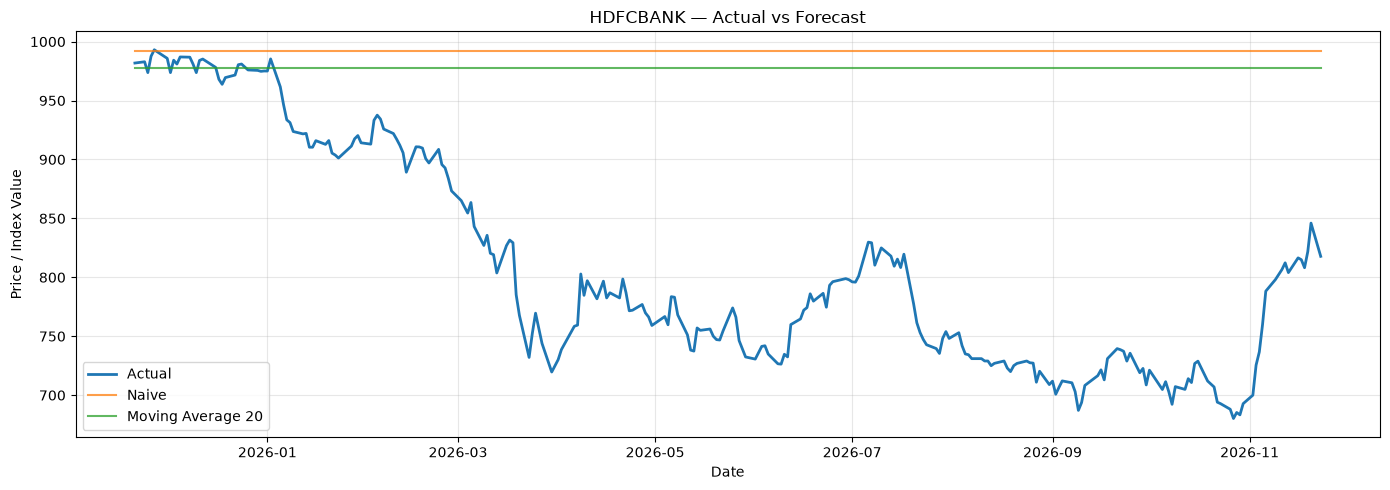

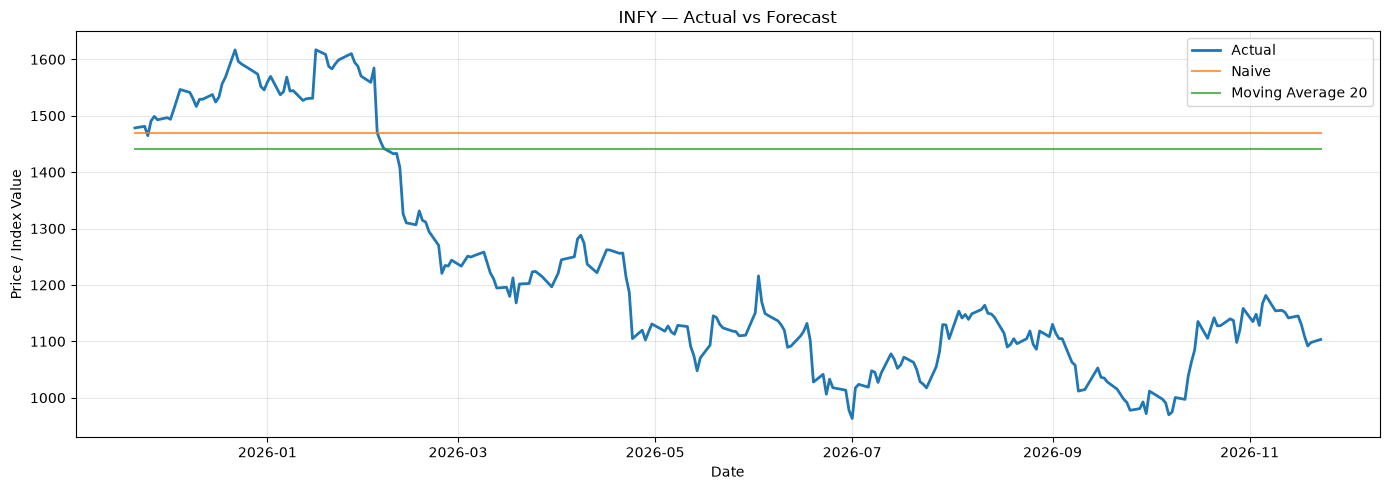

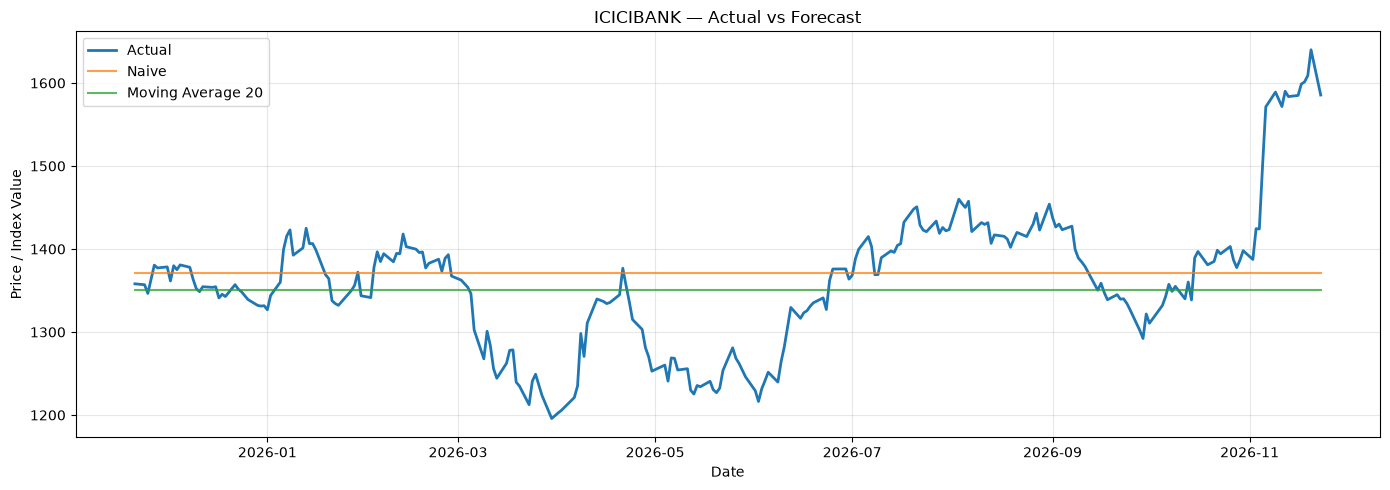

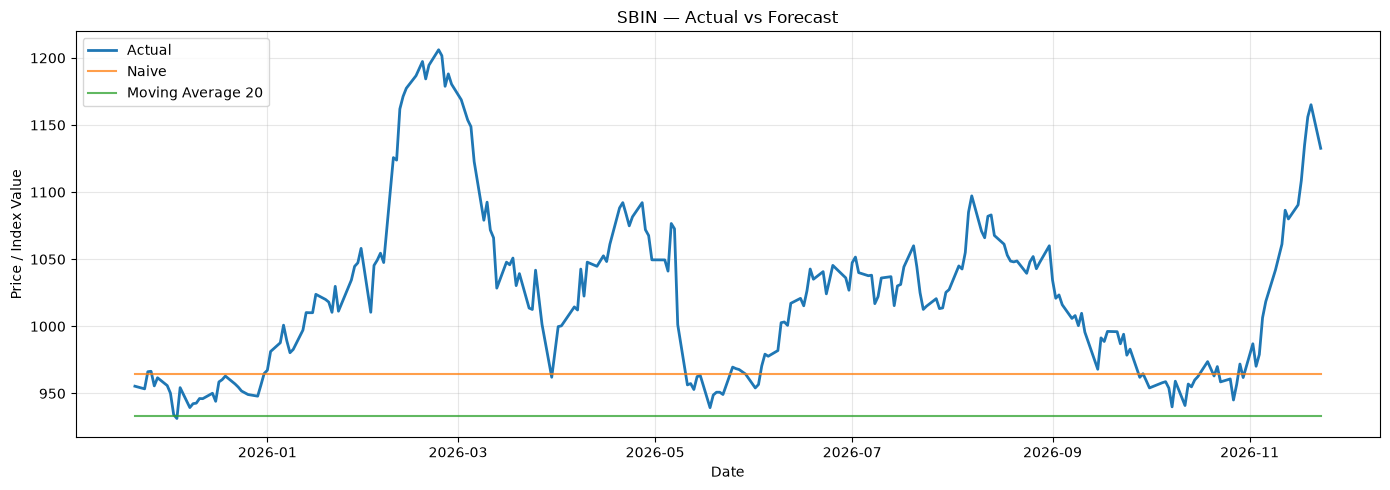

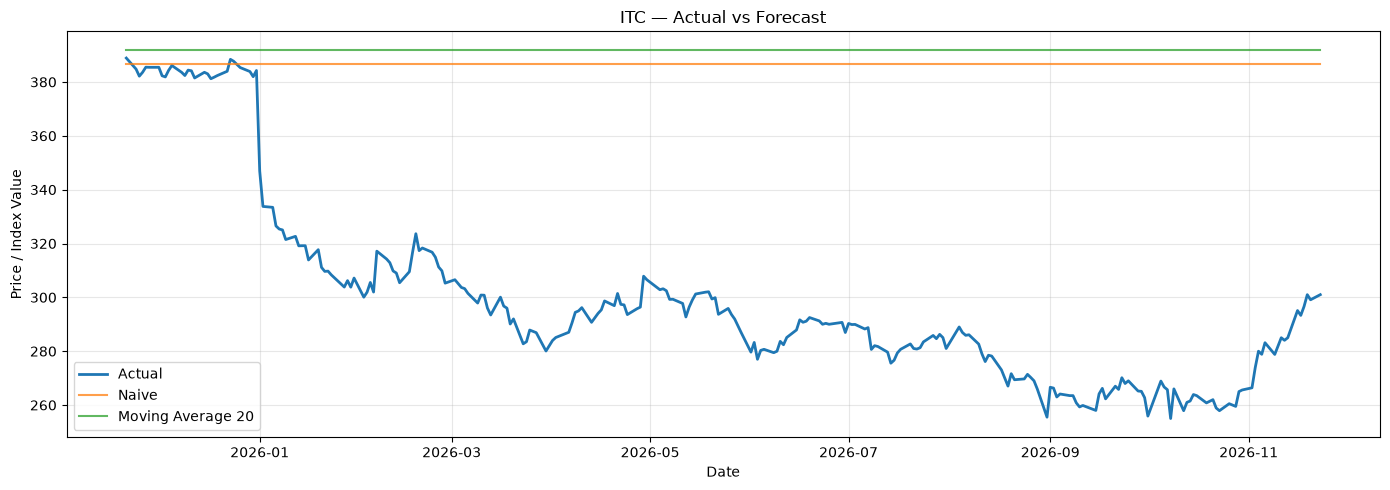

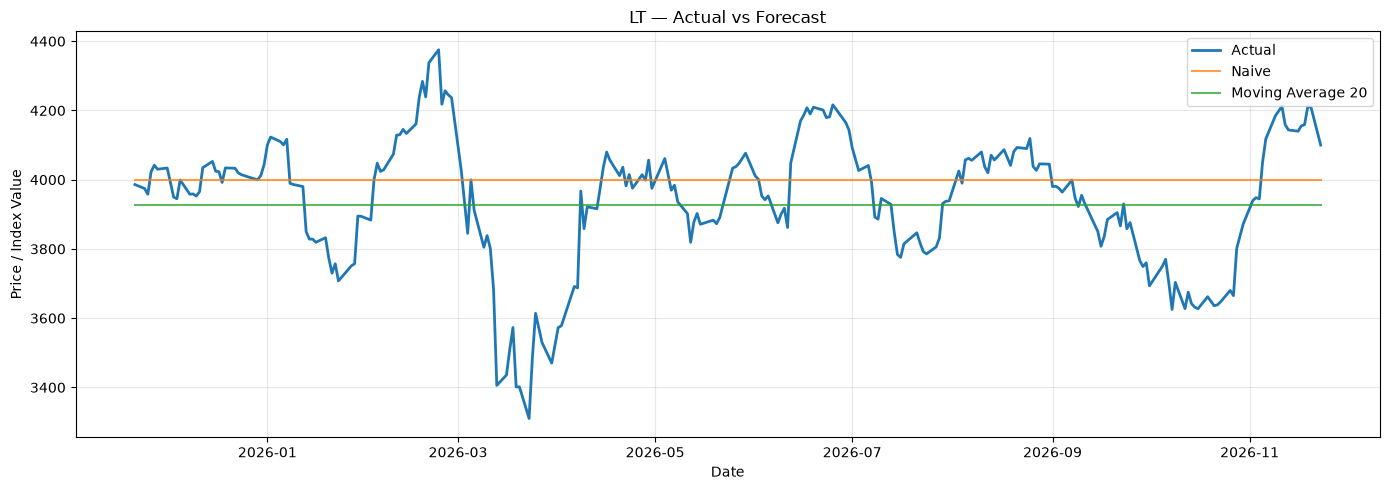

In [15]:
for symbol, data in train_test_data.items():

    test = data["test"]

    plt.figure(figsize=(14, 5))

    plt.plot(
        test.index,
        test.values,
        label="Actual",
        linewidth=2
    )

    for model_name in MODEL_FUNCTIONS.keys():

        key = (symbol, model_name)

        if key in all_predictions:
            plt.plot(
                all_predictions[key].index,
                all_predictions[key].values,
                label=model_name,
                alpha=0.75
            )

    plt.title(f"{symbol} — Actual vs Forecast")
    plt.xlabel("Date")
    plt.ylabel("Price / Index Value")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [16]:
forecast_rows = []

for (symbol, model_name), prediction in all_predictions.items():

    actual = train_test_data[symbol]["test"]

    for date in prediction.index:

        forecast_rows.append({
            "date": date,
            "instrument": symbol,
            "model": model_name,
            "forecast_value": prediction.loc[date],
            "actual_value": actual.loc[date]
        })

forecast_df = pd.DataFrame(forecast_rows)

forecast_file = os.path.join(
    FORECAST_DIR,
    "statistical_forecasts.csv"
)

forecast_df.to_csv(forecast_file, index=False)

print("Saved:", forecast_file)
print("Forecast records:", len(forecast_df))
display(forecast_df.head(10))

Saved: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\data\forecasts\statistical_forecasts.csv
Forecast records: 4958


,date,instrument,model,forecast_value,actual_value
0,2025-11-20,NIFTY50,Naive,26052.650391,26192.150391
1,2025-11-21,NIFTY50,Naive,26052.650391,26068.150391
2,2025-11-24,NIFTY50,Naive,26052.650391,25959.500000
3,2025-11-25,NIFTY50,Naive,26052.650391,25884.800781
4,2025-11-26,NIFTY50,Naive,26052.650391,26205.300781
5,2025-11-27,NIFTY50,Naive,26052.650391,26215.550781
6,2025-11-28,NIFTY50,Naive,26052.650391,26202.949219
7,2025-12-01,NIFTY50,Naive,26052.650391,26175.750000
8,2025-12-02,NIFTY50,Naive,26052.650391,26032.199219
9,2025-12-03,NIFTY50,Naive,26052.650391,25986.000000


In [17]:
best_models = (
    metrics_df
    .dropna(subset=["RMSE"])
    .sort_values(["Instrument", "RMSE"])
    .groupby("Instrument")
    .first()
    .reset_index()
)

best_models.to_csv(
    os.path.join(REPORT_DIR, "best_statistical_models.csv"),
    index=False
)

display(best_models)

,Instrument,Model,MAE,RMSE,MAPE,Directional_Accuracy
0,BANKNIFTY,Moving Average 20,2152.071266,2650.957416,3.834403,49.797571
1,HDFCBANK,Moving Average 20,170.288945,192.962991,22.537887,45.564516
2,ICICIBANK,Moving Average 20,60.118663,80.998852,4.390726,53.225806
3,INFY,Moving Average 20,265.625921,291.471253,23.609636,44.354839
4,ITC,Naive,87.385448,94.016817,30.737768,45.967742
5,LT,Moving Average 20,145.251149,184.835515,3.737082,56.451613
6,NIFTY50,Moving Average 20,1523.574901,1819.337913,6.446532,53.225806
7,RELIANCE,Moving Average 20,147.544428,166.692434,11.342588,49.596774
8,SBIN,Naive,64.355911,86.337084,5.989208,50.403226
9,TCS,Moving Average 20,511.189550,569.797784,22.221302,43.145161


Best NIFTY50 model: Moving Average 20


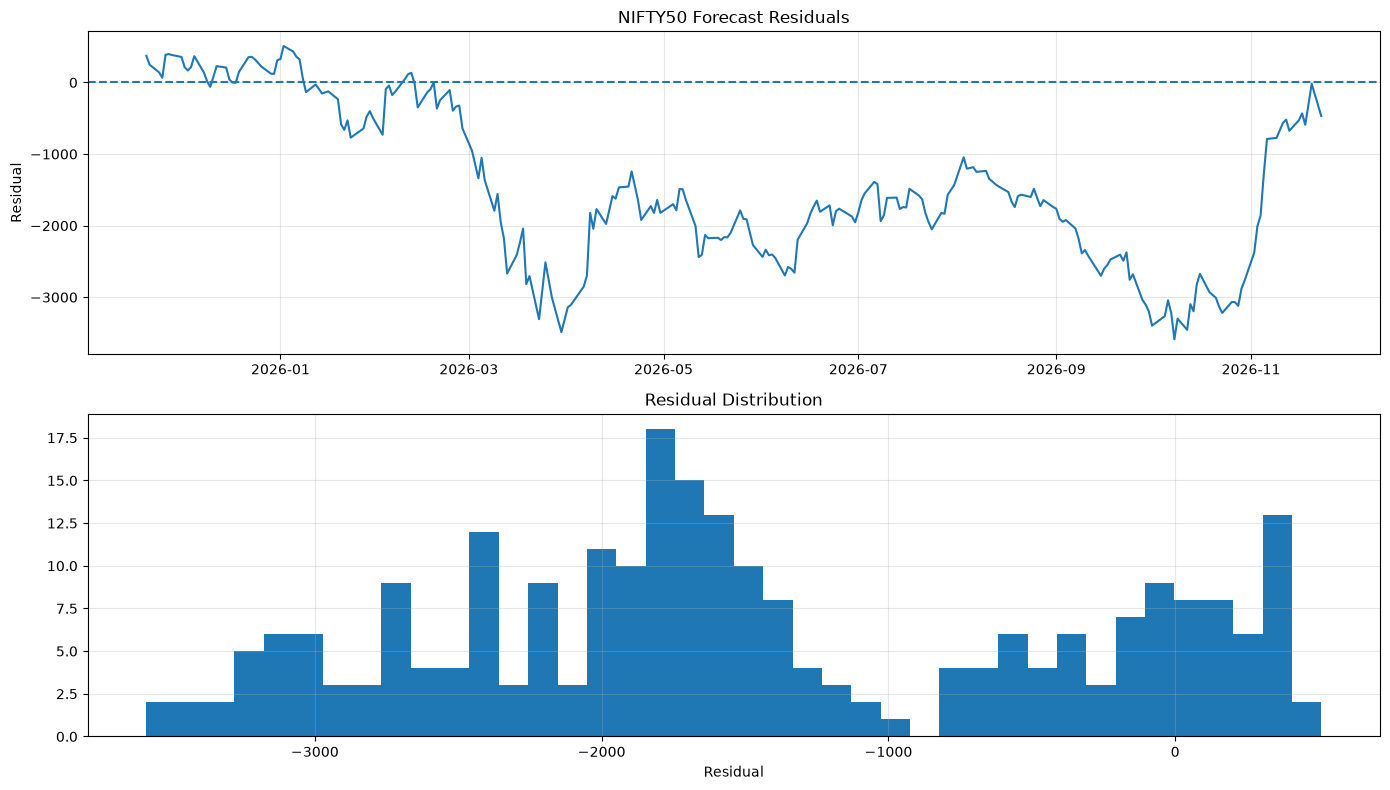

In [18]:
nifty_best_row = (
    metrics_df[metrics_df["Instrument"] == "NIFTY50"]
    .dropna(subset=["RMSE"])
    .sort_values("RMSE")
    .iloc[0]
)

best_nifty_model = nifty_best_row["Model"]

best_nifty_prediction = nifty_predictions[best_nifty_model]

residuals = nifty_test - best_nifty_prediction

print("Best NIFTY50 model:", best_nifty_model)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(residuals.index, residuals.values)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("NIFTY50 Forecast Residuals")
axes[0].set_ylabel("Residual")
axes[0].grid(alpha=0.3)

axes[1].hist(residuals.dropna(), bins=40)
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
summary = {
    "Project": "BharatMarket AI",
    "Notebook": "05 - Statistical Forecasting",
    "Instruments Loaded": len(market_series),
    "Instruments Evaluated": metrics_df["Instrument"].nunique(),
    "Models Evaluated": metrics_df["Model"].nunique(),
    "Train Test Split": "80% / 20%",
    "Forecasting Target": "Adjusted Close where available, otherwise Close",
    "Primary Evaluation Metrics": "MAE, RMSE, MAPE, Directional Accuracy",
    "Forecast File": forecast_file,
    "Metrics File": os.path.join(
        REPORT_DIR,
        "statistical_forecasting_metrics.csv"
    )
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Item", "Value"]
)

display(summary_df)

summary_df.to_csv(
    os.path.join(REPORT_DIR, "notebook_05_summary.csv"),
    index=False
)

print("\nNOTEBOOK 05 COMPLETED")

,Item,Value
0,Project,BharatMarket AI
1,Notebook,05 - Statistical Forecasting
2,Instruments Loaded,10
3,Instruments Evaluated,10
4,Models Evaluated,2
5,Train Test Split,80% / 20%
6,Forecasting Target,"Adjusted Close where available, otherwise Close"
7,Primary Evaluation Metrics,"MAE, RMSE, MAPE, Directional Accuracy"
8,Forecast File,C:\Users\adity\Downloads\Historical data\Bhara...
9,Metrics File,C:\Users\adity\Downloads\Historical data\Bhara...



NOTEBOOK 05 COMPLETED
